In [1]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\yaswa\Diamond_Price_Prediction\.venv\Scripts\python.exe
Python version: 3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]


In [2]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
dataset_path = project_root / "data" / "raw" / "diamonds.csv"

df = pd.read_csv(dataset_path)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

df.head()

Dataset shape: (53940, 10)
Column names: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


# Phase 1 - Data Inspection

### Step 1 - Import the required libraries

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


### Step 2 - Load the dataset 

In [5]:
from pathlib import Path

dataset_path = Path("../data/raw/diamonds.csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (53940, 10)


### step 3 - understand the dataset structure

In [6]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [7]:
df.tail()

,carat,cut,color,clarity,depth,table,price,x,y,z
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64


In [9]:
df.sample(5, random_state = 42)

,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


### step 4 - Inspect dimensions and columns

In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 53940
Number of columns: 10

Column names:
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']


### Step 5 - Inspect the data types

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.7 MB


### step 6 - Missing value Analysis

In [12]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


### Step 7 - Calculate Missing value percentage

In [13]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage
})

print(missing_summary)

         Missing Count  Missing Percentage
carat                0                 0.0
cut                  0                 0.0
color                0                 0.0
clarity              0                 0.0
depth                0                 0.0
table                0                 0.0
price                0                 0.0
x                    0                 0.0
y                    0                 0.0
z                    0                 0.0


### step 8 - Duplicate Record Analysis

In [14]:
# Count completely duplicated rows

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 146


### step 9 - Inspect Duplicate records

In [15]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate rows shape:", duplicate_rows.shape)

duplicate_rows.head(10)

Duplicate rows shape: (289, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
1004,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1005,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
2024,1.52,Good,E,I1,57.3,58.0,3105,7.53,7.42,4.28
2025,1.52,Good,E,I1,57.3,58.0,3105,7.53,7.42,4.28
2182,1.00,Fair,E,SI2,67.0,53.0,3136,6.19,6.13,4.13
2183,1.00,Fair,E,SI2,67.0,53.0,3136,6.19,6.13,4.13
2819,1.00,Fair,F,SI2,65.1,55.0,3265,6.26,6.23,4.07


### Numerical feature statistics

In [20]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


### Categorical Feature statistics

In [21]:
df.describe(include="str")

,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


### Inspect Unique categorical values

In [22]:
categorical_columns = ["cut", "color", "clarity"]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(df[column].unique())

    print(f"\nFrequency distribution of {column}:")
    print(df[column].value_counts())


Unique values in cut:
<ArrowStringArray>
['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Length: 5, dtype: str

Frequency distribution of cut:
cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

Unique values in color:
<ArrowStringArray>
['E', 'I', 'J', 'H', 'F', 'G', 'D']
Length: 7, dtype: str

Frequency distribution of color:
color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

Unique values in clarity:
<ArrowStringArray>
['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Length: 8, dtype: str

Frequency distribution of clarity:
clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64


### Investigate Zero Measurements

In [23]:
dimension_columns = ["x", "y", "z"]

zero_counts = (df[dimension_columns] == 0).sum()

print("Zero measurements:")
print(zero_counts)

Zero measurements:
x     8
y     7
z    20
dtype: int64


In [24]:
zero_dimension_rows = df[
    (df[dimension_columns] == 0).any(axis=1)
]

print("Records containing at least one zero dimension:",
      zero_dimension_rows.shape[0])

zero_dimension_rows.head(20)

Records containing at least one zero dimension: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


### Investigate unusually large dimensions

In [25]:
print("10 largest Y measurements:")

display(
    df.nlargest(10, "y")[
        ["carat", "cut", "price", "x", "y", "z"]
    ]
)

10 largest Y measurements:


,carat,cut,price,x,y,z
24067,2.00,Premium,12210,8.09,58.90,8.06
49189,0.51,Ideal,2075,5.15,31.80,5.12
27415,5.01,Fair,18018,10.74,10.54,6.98
27630,4.50,Fair,18531,10.23,10.16,6.72
25998,4.01,Premium,15223,10.14,10.10,6.17
25999,4.01,Premium,15223,10.02,9.94,6.24
26444,4.00,Very Good,15984,10.01,9.94,6.31
27130,4.13,Fair,17329,10.00,9.85,6.43
26534,3.67,Premium,16193,9.86,9.81,6.13
27679,3.51,Premium,18701,9.66,9.63,6.03


In [26]:
print("10 largest Z measurements:")

display(
    df.nlargest(10, "z")[
        ["carat", "cut", "price", "x", "y", "z"]
    ]
)

10 largest Z measurements:


,carat,cut,price,x,y,z
48410,0.51,Very Good,1970,5.12,5.15,31.80
24067,2.00,Premium,12210,8.09,58.90,8.06
27415,5.01,Fair,18018,10.74,10.54,6.98
27630,4.50,Fair,18531,10.23,10.16,6.72
27130,4.13,Fair,17329,10.00,9.85,6.43
23644,3.65,Fair,11668,9.53,9.48,6.38
26444,4.00,Very Good,15984,10.01,9.94,6.31
26431,3.40,Fair,15964,9.42,9.34,6.27
25999,4.01,Premium,15223,10.02,9.94,6.24
25998,4.01,Premium,15223,10.14,10.10,6.17


### Plotting categorical distributions

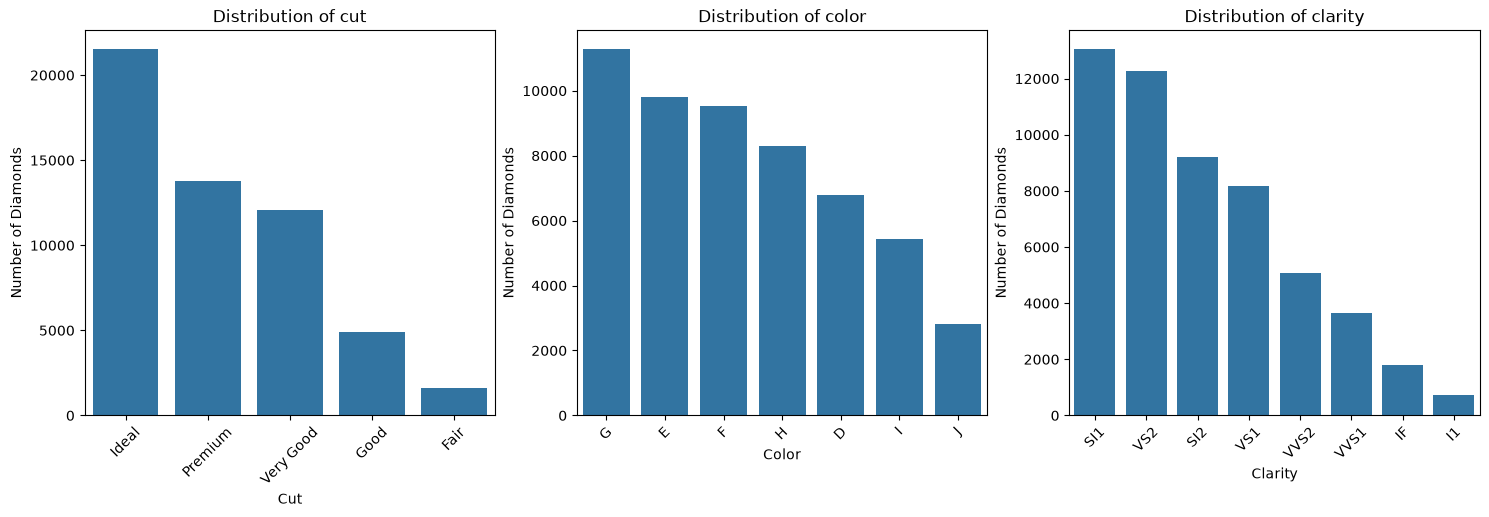

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, categorical_columns):

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column.capitalize())
    ax.set_ylabel("Number of Diamonds")
    ax.tick_params(axis="x", rotation=45)

### Verify suspicious records

In [28]:
suspicious_indices = [24067, 49189, 48410]

suspicious_records = df.loc[suspicious_indices]

display(suspicious_records)

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80


### Identify all records with unusually large dimensions

In [29]:
dimension_columns = ["x", "y", "z"]

large_dimension_records = df[
    (df[dimension_columns] > 15).any(axis=1)
]

print("Records with dimensions greater than 15 mm:",
      large_dimension_records.shape[0])

display(large_dimension_records)

Records with dimensions greater than 15 mm: 3


,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


Why use 15 mm?

This is an investigation threshold, not a universal diamond-quality rule. It helps us locate extreme measurements that need manual inspection.

In [30]:
zero_mask = (df[dimension_columns] == 0).any(axis=1)

large_mask = (df[dimension_columns] > 15).any(axis=1)

print("Zero-dimension records:", zero_mask.sum())

print("Large-dimension records:", large_mask.sum())

print("Records satisfying both conditions:",
      (zero_mask & large_mask).sum())

Zero-dimension records: 20
Large-dimension records: 3
Records satisfying both conditions: 0


## Investigate Target variable

In [31]:
print("Price statistics:")

print(df["price"].describe())

Price statistics:
count    53940.000000
mean      3932.799722
std       3989.439738
min        326.000000
25%        950.000000
50%       2401.000000
75%       5324.250000
max      18823.000000
Name: price, dtype: float64


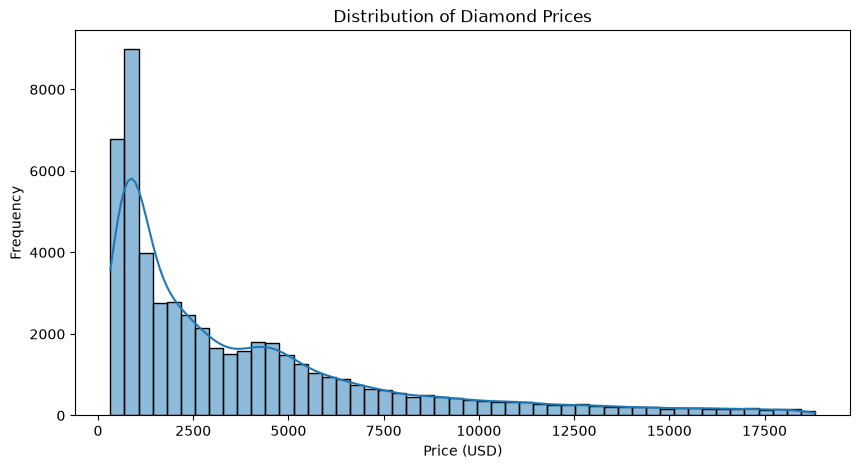

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of Diamond Prices")
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")

plt.show()

## Statistical outlier analysis using IQR

### Create boxplots for numerical features

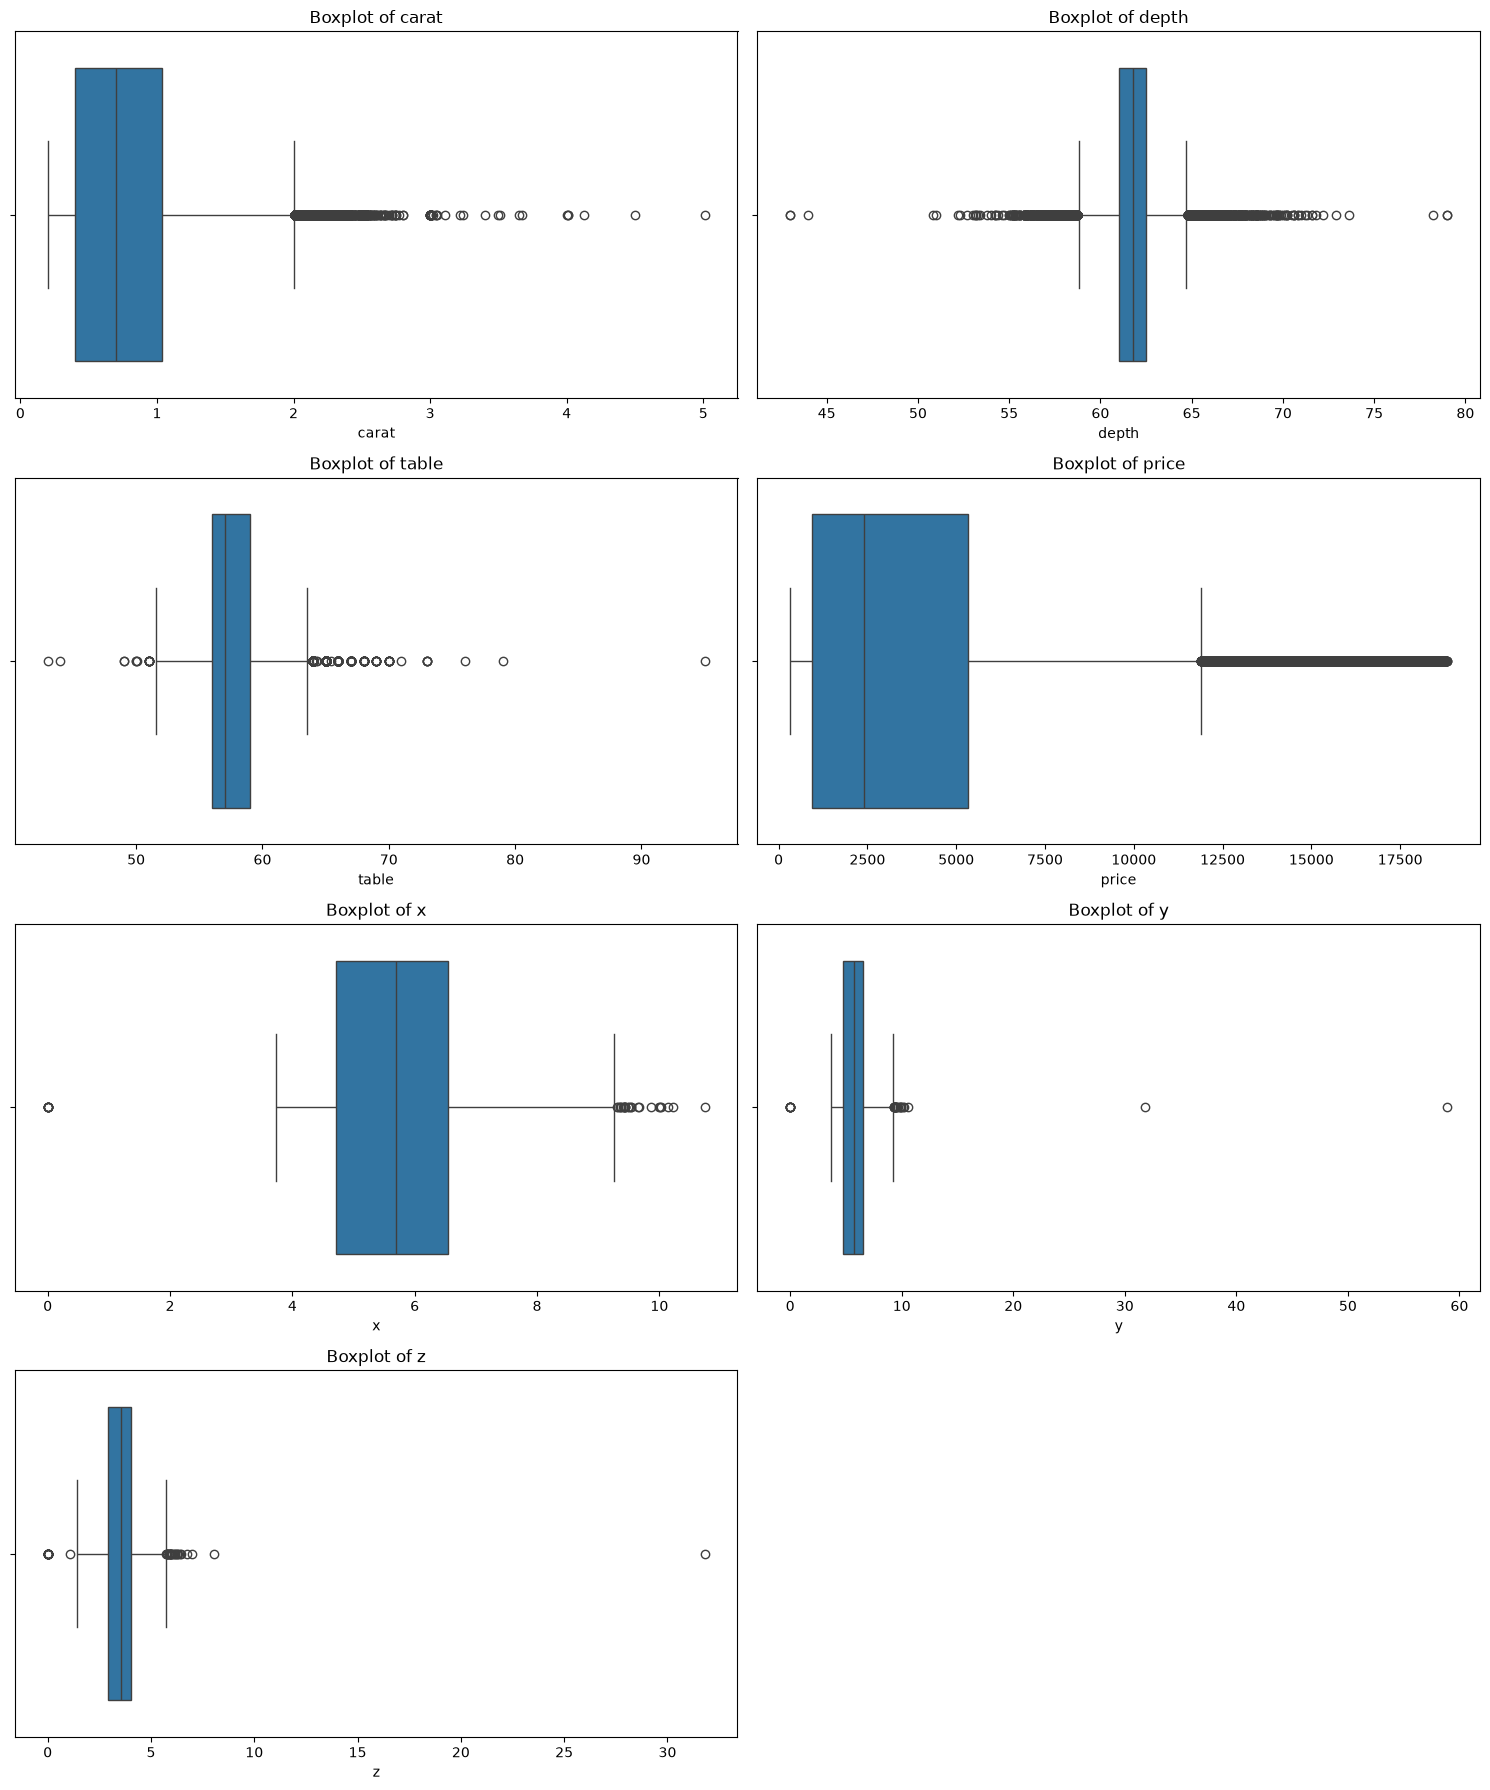

In [33]:
numerical_columns = [
    "carat", "depth", "table",
    "price", "x", "y", "z"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 18))

axes = axes.flatten()

for i, column in enumerate(numerical_columns):

    sns.boxplot(
        data=df,
        x=column,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {column}")

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Calculate IQR boundaries and outlier counts

In [34]:
outlier_summary = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(df)
    ) * 100

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,carat,0.40,1.04,0.64,-0.56,2.00,1889,3.50
1,depth,61.00,62.50,1.50,58.75,64.75,2545,4.72
2,table,56.00,59.00,3.00,51.50,63.50,605,1.12
3,price,950.00,5324.25,4374.25,-5611.38,11885.62,3540,6.56
4,x,4.71,6.54,1.83,1.96,9.28,32,0.06
5,y,4.72,6.54,1.82,1.99,9.27,29,0.05
6,z,2.91,4.04,1.13,1.22,5.74,49,0.09


### Investigate price skewness

In [35]:
print("Price skewness:", df["price"].skew())

print("Price kurtosis:", df["price"].kurtosis())

Price skewness: 1.6183952833835276
Price kurtosis: 2.177695759248686


### Correlation analysis

In [36]:
numerical_columns = [
    "carat", "depth", "table",
    "price", "x", "y", "z"
]

correlation_matrix = df[numerical_columns].corr(
    method="pearson"
)

display(correlation_matrix.round(3))

,carat,depth,table,price,x,y,z
carat,1.000,0.028,0.182,0.922,0.975,0.952,0.953
depth,0.028,1.000,-0.296,-0.011,-0.025,-0.029,0.095
table,0.182,-0.296,1.000,0.127,0.195,0.184,0.151
price,0.922,-0.011,0.127,1.000,0.884,0.865,0.861
x,0.975,-0.025,0.195,0.884,1.000,0.975,0.971
y,0.952,-0.029,0.184,0.865,0.975,1.000,0.952
z,0.953,0.095,0.151,0.861,0.971,0.952,1.000


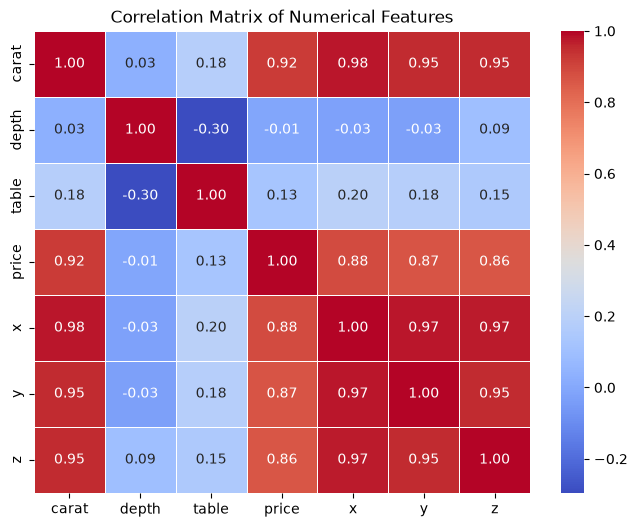

In [38]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")

plt.show()

### Investigate carat versus price

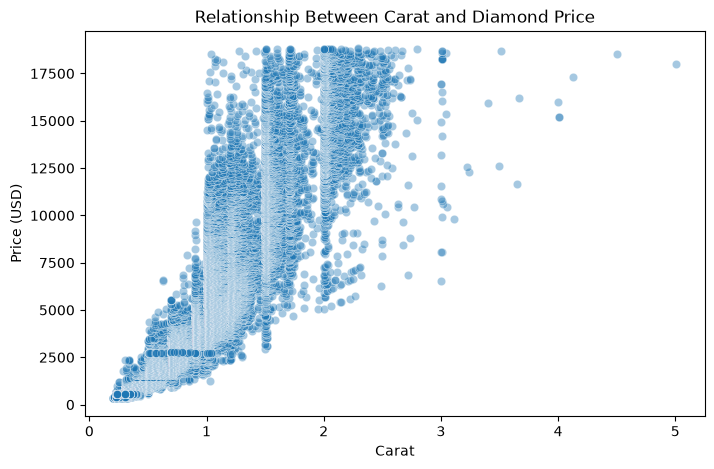

In [40]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="carat",
    y="price",
    alpha=0.4
)

plt.title("Relationship Between Carat and Diamond Price")
plt.xlabel("Carat")
plt.ylabel("Price (USD)")

plt.show()

### Investigate physical dimensions versus price

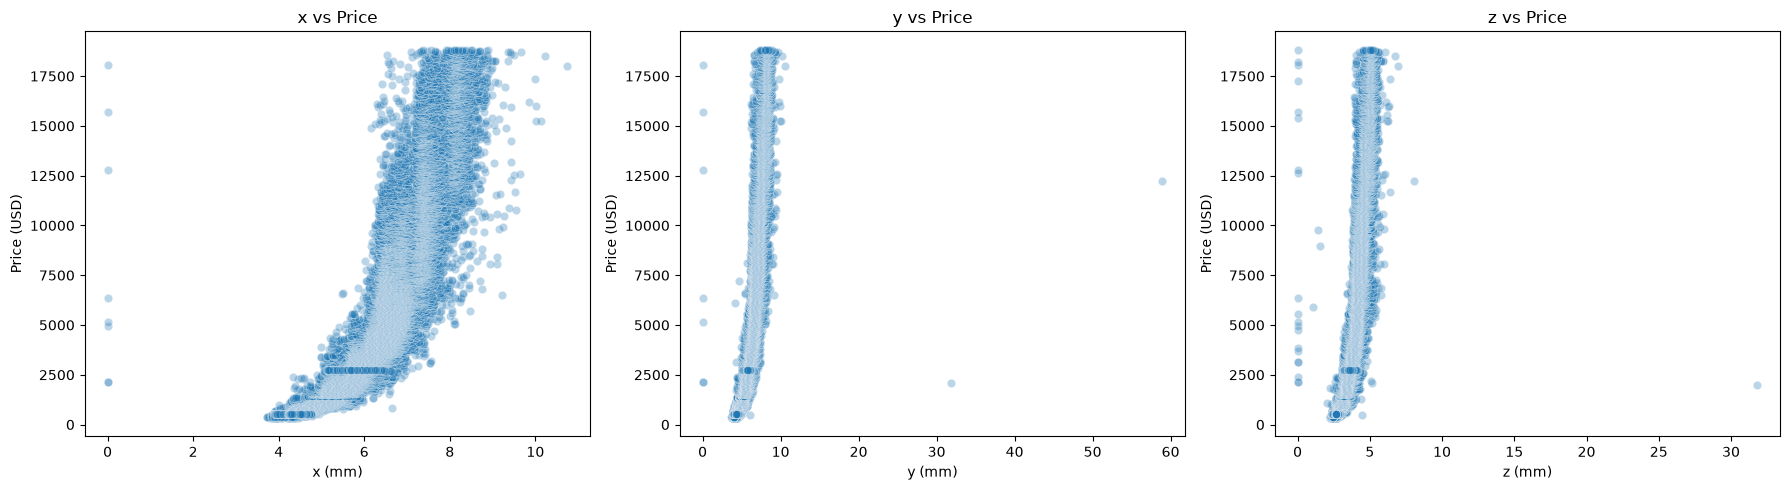

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

dimension_columns = ["x", "y", "z"]

for ax, column in zip(axes, dimension_columns):

    sns.scatterplot(
        data=df,
        x=column,
        y="price",
        alpha=0.3,
        ax=ax
    )

    ax.set_title(f"{column} vs Price")
    ax.set_xlabel(f"{column} (mm)")
    ax.set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

### Understand price differences across categorical features

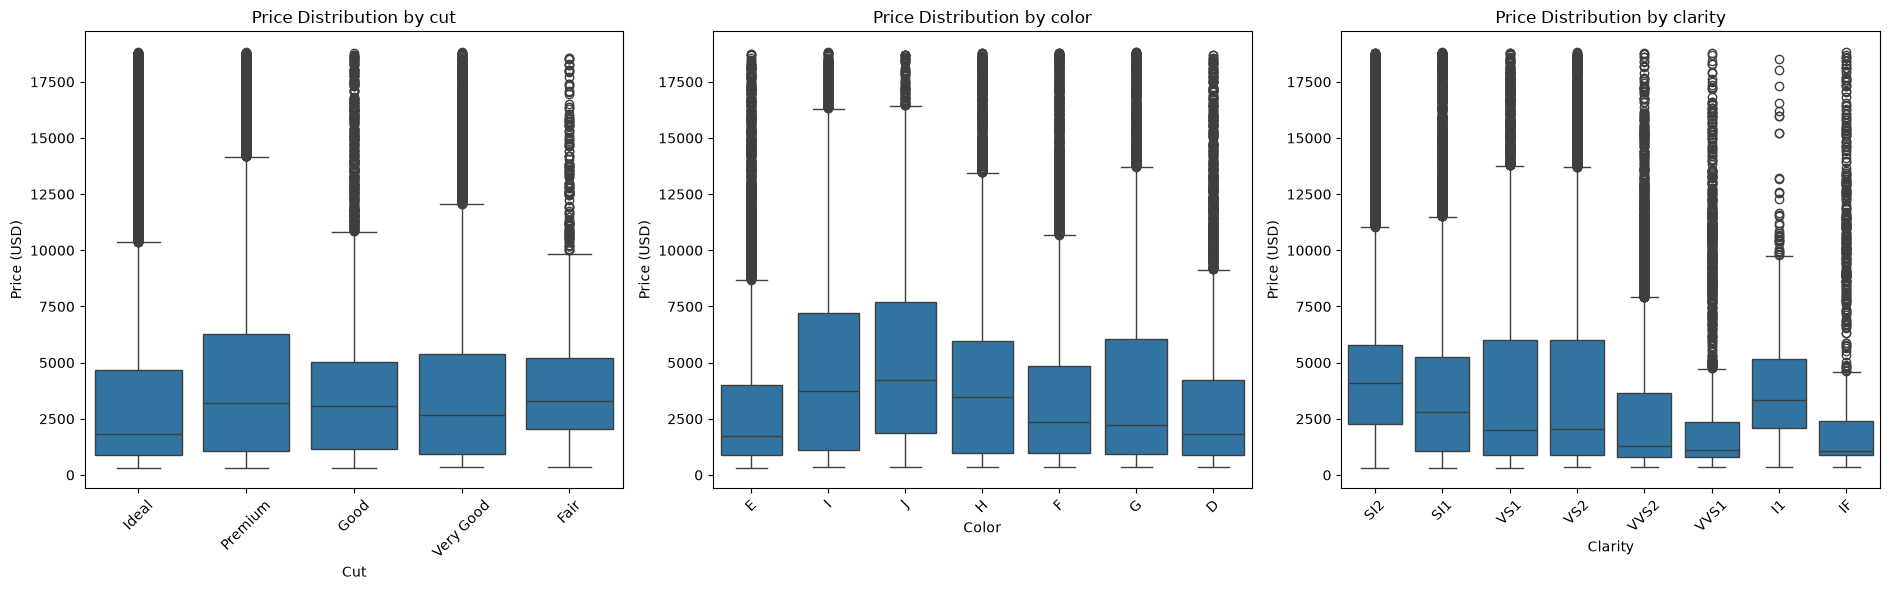

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

categorical_columns = ["cut", "color", "clarity"]

for ax, column in zip(axes, categorical_columns):

    sns.boxplot(
        data=df,
        x=column,
        y="price",
        ax=ax
    )

    ax.set_title(f"Price Distribution by {column}")
    ax.set_xlabel(column.capitalize())
    ax.set_ylabel("Price (USD)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [43]:
categorical_columns = ["cut", "color", "clarity"]

for column in categorical_columns:

    summary = (
        df.groupby(column)["price"]
        .agg(["count", "mean", "median"])
        .sort_values("median", ascending=False)
    )

    print(f"\nPrice statistics by {column}:")
    display(summary.round(2))


Price statistics by cut:


,count,mean,median
cut,,,
Fair,1610,4358.76,3282.0
Premium,13791,4584.26,3185.0
Good,4906,3928.86,3050.5
Very Good,12082,3981.76,2648.0
Ideal,21551,3457.54,1810.0



Price statistics by color:


,count,mean,median
color,,,
J,2808,5323.82,4234.0
I,5422,5091.87,3730.0
H,8304,4486.67,3460.0
F,9542,3724.89,2343.5
G,11292,3999.14,2242.0
D,6775,3169.95,1838.0
E,9797,3076.75,1739.0



Price statistics by clarity:


,count,mean,median
clarity,,,
SI2,9194,5063.03,4072.0
I1,741,3924.17,3344.0
SI1,13065,3996.00,2822.0
VS2,12258,3924.99,2054.0
VS1,8171,3839.46,2005.0
VVS2,5066,3283.74,1311.0
VVS1,3655,2523.11,1093.0
IF,1790,2864.84,1080.0


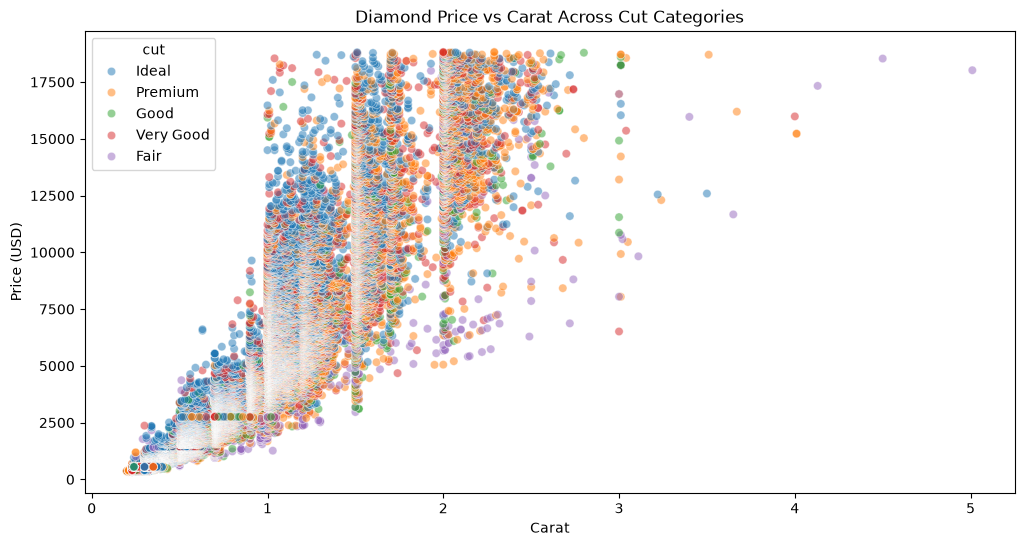

In [44]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="carat",
    y="price",
    hue="cut",
    alpha=0.5
)

plt.title("Diamond Price vs Carat Across Cut Categories")
plt.xlabel("Carat")
plt.ylabel("Price (USD)")

plt.show()

# Phase 2 – Data cleaning and preparation

In [45]:
# Preserve the original dataset
df_original = df.copy()

# Create a separate working dataset
df_working = df.copy()

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_working.shape)

print("Original dataset remains unchanged:",
      df_original.equals(df))

Original dataset shape: (53940, 10)
Working dataset shape: (53940, 10)
Original dataset remains unchanged: True


### Prepare a leakage-aware train-test split

In [46]:
from sklearn.model_selection import GroupShuffleSplit

# Create a unique group identifier for identical records
duplicate_groups = pd.util.hash_pandas_object(
    df_working,
    index=False
)

# Split groups rather than individual rows
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(
        df_working,
        groups=duplicate_groups
    )
)

df_train = df_working.iloc[train_indices].copy()
df_test = df_working.iloc[test_indices].copy()

print("Training dataset:", df_train.shape)
print("Testing dataset:", df_test.shape)

Training dataset: (40457, 10)
Testing dataset: (13483, 10)


### Verify the split

In [47]:
print("Training percentage:",
      round(len(df_train) / len(df_working) * 100, 2))

print("Testing percentage:",
      round(len(df_test) / len(df_working) * 100, 2))

print("Training shape:", df_train.shape)
print("Testing shape:", df_test.shape)

Training percentage: 75.0
Testing percentage: 25.0
Training shape: (40457, 10)
Testing shape: (13483, 10)


In [48]:
train_groups = set(duplicate_groups.iloc[train_indices])
test_groups = set(duplicate_groups.iloc[test_indices])

print("Overlapping duplicate groups:",
      len(train_groups.intersection(test_groups)))

Overlapping duplicate groups: 0


### Separate input features and target

In [49]:
X_train = df_train.drop(columns=["price"])
y_train = df_train["price"].copy()

X_test = df_test.drop(columns=["price"])
y_test = df_test["price"].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40457, 9)
X_test: (13483, 9)
y_train: (40457,)
y_test: (13483,)


### Check target distribution in both partitions

In [50]:
print("Training target statistics:")
display(y_train.describe())

print("\nTesting target statistics:")
display(y_test.describe())

Training target statistics:


count    40457.000000
mean      3914.468201
std       3976.897798
min        327.000000
25%        952.000000
50%       2394.000000
75%       5288.000000
max      18818.000000
Name: price, dtype: float64


Testing target statistics:


count    13483.000000
mean      3987.805162
std       4026.486035
min        326.000000
25%        945.000000
50%       2450.000000
75%       5443.000000
max      18823.000000
Name: price, dtype: float64

### Handle Invalid Physical Measurements

In [51]:
# Physical dimension columns
dimension_columns = ["x", "y", "z"]

# Identify invalid measurements in training data
train_invalid_mask = (
    (df_train[dimension_columns] <= 0).any(axis=1) |
    (df_train[dimension_columns] > 15).any(axis=1)
)

# Identify invalid measurements in testing data
test_invalid_mask = (
    (df_test[dimension_columns] <= 0).any(axis=1) |
    (df_test[dimension_columns] > 15).any(axis=1)
)

print("Invalid training records:", train_invalid_mask.sum())
print("Invalid testing records:", test_invalid_mask.sum())

print("Total invalid records:",
      train_invalid_mask.sum() + test_invalid_mask.sum())

Invalid training records: 11
Invalid testing records: 12
Total invalid records: 23


In [52]:
# Create cleaned training dataset
df_train_clean = df_train.loc[
    ~train_invalid_mask
].copy()

# Create cleaned testing dataset
df_test_clean = df_test.loc[
    ~test_invalid_mask
].copy()

print("Training dataset before cleaning:", df_train.shape)
print("Training dataset after cleaning:", df_train_clean.shape)

print("\nTesting dataset before cleaning:", df_test.shape)
print("Testing dataset after cleaning:", df_test_clean.shape)

Training dataset before cleaning: (40457, 10)
Training dataset after cleaning: (40446, 10)

Testing dataset before cleaning: (13483, 10)
Testing dataset after cleaning: (13471, 10)


In [53]:
print("Remaining zero measurements:")

print(
    (df_train_clean[dimension_columns] == 0).sum()
)

print("\nRemaining dimensions greater than 15:")

print(
    (df_train_clean[dimension_columns] > 15).sum()
)

Remaining zero measurements:
x    0
y    0
z    0
dtype: int64

Remaining dimensions greater than 15:
x    0
y    0
z    0
dtype: int64


In [54]:
cleaning_report = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Original Records": [
        len(df_train),
        len(df_test)
    ],
    "Invalid Records Removed": [
        train_invalid_mask.sum(),
        test_invalid_mask.sum()
    ],
    "Remaining Records": [
        len(df_train_clean),
        len(df_test_clean)
    ]
})

display(cleaning_report)

,Dataset,Original Records,Invalid Records Removed,Remaining Records
0,Training,40457,11,40446
1,Testing,13483,12,13471


### Separate cleaned features and targets

In [55]:
# Training features and target
X_train_clean = df_train_clean.drop(
    columns=["price"]
)

y_train_clean = df_train_clean["price"]

# Testing features and target
X_test_clean = df_test_clean.drop(
    columns=["price"]
)

y_test_clean = df_test_clean["price"]

print("X_train_clean:", X_train_clean.shape)
print("X_test_clean:", X_test_clean.shape)

print("y_train_clean:", y_train_clean.shape)
print("y_test_clean:", y_test_clean.shape)

X_train_clean: (40446, 9)
X_test_clean: (13471, 9)
y_train_clean: (40446,)
y_test_clean: (13471,)


## Phase 3 – Feature engineering and preprocessing

### Identify numerical and categorical features

In [56]:
# Identify numerical and categorical columns

numerical_features = X_train_clean.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['carat', 'depth', 'table', 'x', 'y', 'z']

Categorical features: ['cut', 'color', 'clarity']

Number of numerical features: 6
Number of categorical features: 3


### Feature engineering – Calculate diamond volume

In [57]:
# Create independent feature datasets

X_train_fe = X_train_clean.copy()
X_test_fe = X_test_clean.copy()

# Calculate approximate bounding-box volume

X_train_fe["volume"] = (
    X_train_fe["x"] *
    X_train_fe["y"] *
    X_train_fe["z"]
)

X_test_fe["volume"] = (
    X_test_fe["x"] *
    X_test_fe["y"] *
    X_test_fe["z"]
)

print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

display(X_train_fe.head())

Training shape: (40446, 10)
Testing shape: (13471, 10)


,carat,cut,color,clarity,depth,table,x,y,z,volume
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31,38.076885
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63,46.724580
5,0.24,Very Good,J,VVS2,62.8,57.0,3.94,3.96,2.48,38.693952
6,0.24,Very Good,I,VVS1,62.3,57.0,3.95,3.98,2.47,38.830870
7,0.26,Very Good,H,SI1,61.9,55.0,4.07,4.11,2.53,42.321081


In [61]:
cut_order = [
    "Fair",
    "Good",
    "Very Good",
    "Premium",
    "Ideal"
]

In [62]:
color_order = [
    "J",
    "I",
    "H",
    "G",
    "F",
    "E",
    "D"
]

In [63]:
clarity_order = [
    "I1",
    "SI2",
    "SI1",
    "VS2",
    "VS1",
    "VVS2",
    "VVS1",
    "IF"
]

### Build our preprocessing pipelines

In [58]:
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
    OneHotEncoder
)

from sklearn.pipeline import Pipeline

### Define numerical and categorical features

In [59]:
numerical_features = [
    "carat",
    "depth",
    "table",
    "x",
    "y",
    "z",
    "volume"
]

categorical_features = [
    "cut",
    "color",
    "clarity"
]

### Create ordinal encoding configuration

In [64]:
ordinal_categories = [
    cut_order,
    color_order,
    clarity_order
]

ordinal_encoder = OrdinalEncoder(
    categories=ordinal_categories,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

### Build the ordinal preprocessing pipeline

In [65]:
ordinal_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            ordinal_encoder,
            categorical_features
        )
    ],
    remainder="drop"
)

### Build the one-hot preprocessing pipeline

In [66]:
onehot_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

### Verify the preprocessing pipelines

In [67]:
X_train_ordinal = ordinal_preprocessor.fit_transform(
    X_train_fe
)

X_test_ordinal = ordinal_preprocessor.transform(
    X_test_fe
)

print("Ordinal training shape:", X_train_ordinal.shape)
print("Ordinal testing shape:", X_test_ordinal.shape)

Ordinal training shape: (40446, 10)
Ordinal testing shape: (13471, 10)


### Fit one-hot preprocessing on training data

In [68]:
X_train_onehot = onehot_preprocessor.fit_transform(
    X_train_fe
)

X_test_onehot = onehot_preprocessor.transform(
    X_test_fe
)

print("One-hot training shape:", X_train_onehot.shape)
print("One-hot testing shape:", X_test_onehot.shape)

One-hot training shape: (40446, 27)
One-hot testing shape: (13471, 27)


## Build our first KNN regression model

In [69]:
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

### Create the baseline KNN model

In [70]:
# Create baseline KNN model

knn_baseline = KNeighborsRegressor(
    n_neighbors=5,
    weights="uniform",
    metric="minkowski",
    p=2
)

# Create complete ML pipeline

baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", ordinal_preprocessor),
        ("model", knn_baseline)
    ]
)

print(baseline_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['carat', 'depth', 'table',
                                                   'x', 'y', 'z', 'volume']),
                                                 ('cat',
                                                  OrdinalEncoder(categories=[['Fair',
                                                                              'Good',
                                                                              'Very '
                                                                              'Good',
                                                                              'Premium',
                                                                              'Ideal'],
                                                                             ['J',
                                                                           

### Train the baseline model

In [71]:
baseline_pipeline.fit(
    X_train_fe,
    y_train_clean
)

print("Baseline KNN model trained successfully!")

Baseline KNN model trained successfully!


### Evaluate the baseline model

In [72]:
# Generate predictions

y_pred_baseline = baseline_pipeline.predict(
    X_test_fe
)

# Calculate evaluation metrics

mae = mean_absolute_error(
    y_test_clean,
    y_pred_baseline
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_clean,
        y_pred_baseline
    )
)

r2 = r2_score(
    y_test_clean,
    y_pred_baseline
)

print("BASELINE KNN REGRESSION RESULTS")
print("-" * 40)

print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")

BASELINE KNN REGRESSION RESULTS
----------------------------------------
MAE:  $370.63
RMSE: $689.81
R2 Score: 0.9706


### Understand individual predictions

In [73]:
comparison_df = pd.DataFrame({
    "Actual Price": y_test_clean.values[:15],
    "Predicted Price": y_pred_baseline[:15]
})

comparison_df["Absolute Error"] = (
    comparison_df["Actual Price"] -
    comparison_df["Predicted Price"]
).abs()

display(comparison_df.round(2))

,Actual Price,Predicted Price,Absolute Error
0,326,483.8,157.8
1,326,649.2,323.2
2,335,415.8,80.8
3,340,447.4,107.4
4,342,629.4,287.4
5,344,457.4,113.4
6,357,500.0,143.0
7,402,473.4,71.4
8,402,528.6,126.6
9,403,386.6,16.4


## Evaluate baseline KNN using cross-validation

In [74]:
from sklearn.model_selection import cross_validate

In [75]:
cv_results = cross_validate(
    estimator=baseline_pipeline,
    X=X_train_fe,
    y=y_train_clean,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

### Calculate cross-validation results

In [76]:
cv_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],

    "Mean": [
        -cv_results["test_mae"].mean(),
        -cv_results["test_rmse"].mean(),
        cv_results["test_r2"].mean()
    ],

    "Standard Deviation": [
        cv_results["test_mae"].std(),
        cv_results["test_rmse"].std(),
        cv_results["test_r2"].std()
    ]
})

display(cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,MAE,1105.7182,793.6522
1,RMSE,1535.9120,1276.3020
2,R2,-0.0549,0.6744


In [77]:
print(
    "Mean Training R2:",
    round(cv_results["train_r2"].mean(), 4)
)

print(
    "Mean Validation R2:",
    round(cv_results["test_r2"].mean(), 4)
)

Mean Training R2: 0.9806
Mean Validation R2: -0.0549


### Verify whether the dataset is sorted by price

In [78]:
print("Is original dataset sorted by price?",
      df["price"].is_monotonic_increasing)

print("\nFirst 10 prices:")
print(df["price"].head(10).tolist())

print("\nLast 10 prices:")
print(df["price"].tail(10).tolist())

Is original dataset sorted by price? False

First 10 prices:
[326, 326, 327, 334, 335, 336, 336, 337, 337, 338]

Last 10 prices:
[2756, 2756, 2757, 2757, 2757, 2757, 2757, 2757, 2757, 2757]


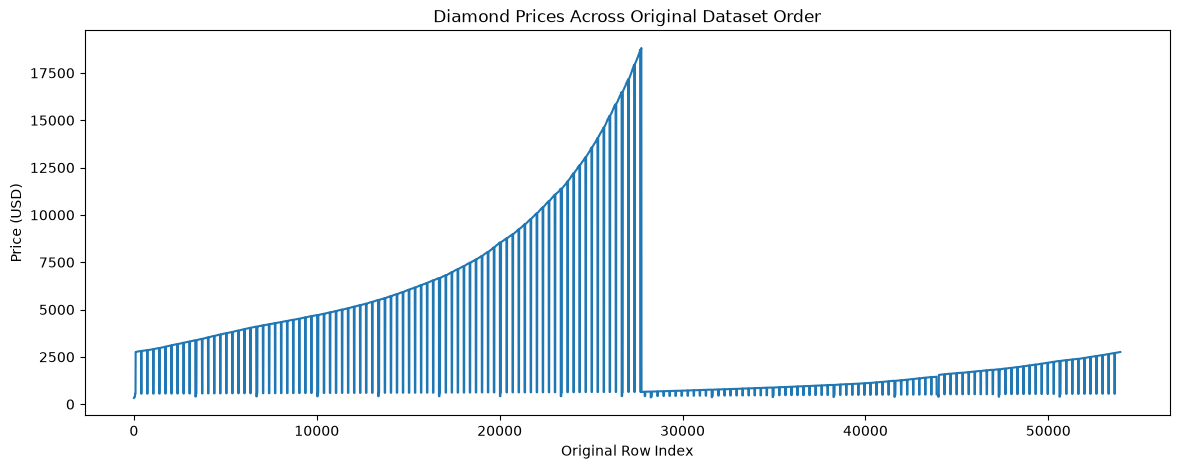

In [79]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_train_clean.index,
    df_train_clean["price"]
)

plt.title("Diamond Prices Across Original Dataset Order")
plt.xlabel("Original Row Index")
plt.ylabel("Price (USD)")

plt.show()

### Correct cross-validation

In [80]:
from sklearn.model_selection import GroupKFold

In [81]:
cv_groups = pd.util.hash_pandas_object(
    df_train_clean,
    index=False
)

print("Training observations:", len(X_train_fe))
print("Unique duplicate groups:", cv_groups.nunique())

Training observations: 40446
Unique duplicate groups: 40334


In [82]:
group_cv = GroupKFold(n_splits=5)

In [83]:
cv_results_corrected = cross_validate(
    estimator=baseline_pipeline,
    X=X_train_fe,
    y=y_train_clean,
    groups=cv_groups,
    cv=group_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

### Compare corrected results

In [84]:
corrected_cv_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],

    "Mean": [
        -cv_results_corrected["test_mae"].mean(),
        -cv_results_corrected["test_rmse"].mean(),
        cv_results_corrected["test_r2"].mean()
    ],

    "Standard Deviation": [
        cv_results_corrected["test_mae"].std(),
        cv_results_corrected["test_rmse"].std(),
        cv_results_corrected["test_r2"].std()
    ]
})

display(corrected_cv_summary.round(4))

,Metric,Mean,Standard Deviation
0,MAE,376.5958,4.0886
1,RMSE,704.6149,14.0940
2,R2,0.9685,0.0014


In [85]:
print(
    "Mean Training R2:",
    round(cv_results_corrected["train_r2"].mean(), 4)
)

print(
    "Mean Validation R2:",
    round(cv_results_corrected["test_r2"].mean(), 4)
)

Mean Training R2: 0.9796
Mean Validation R2: 0.9685


In [86]:
fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": -cv_results_corrected["test_mae"],
    "RMSE": -cv_results_corrected["test_rmse"],
    "R2": cv_results_corrected["test_r2"]
})

display(fold_results.round(4))

,Fold,MAE,RMSE,R2
0,1,376.2974,713.1044,0.9678
1,2,373.6553,691.9724,0.9696
2,3,370.9333,691.9384,0.9696
3,4,379.7884,697.8805,0.9696
4,5,382.3045,728.1787,0.9660


## KNN hyperparameter tuning

In [87]:
from sklearn.model_selection import GridSearchCV

In [88]:
param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

### Configure GridSearchCV

In [89]:
knn_grid_search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=param_grid,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    refit="MAE",
    cv=group_cv,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

### Run hyperparameter tuning

In [90]:
knn_grid_search.fit(
    X_train_fe,
    y_train_clean,
    groups=cv_groups
)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [3, 5, ...], 'model__p': [1, 2], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'MAE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` defau

### Inspect the best parameters

In [91]:
print("Best Parameters:")
print(knn_grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-knn_grid_search.best_score_)

Best Parameters:
{'model__n_neighbors': 9, 'model__p': 1, 'model__weights': 'distance'}

Best Cross-Validation MAE:
317.7310854234814


### Display the top 10 configurations

In [92]:
knn_results = pd.DataFrame(knn_grid_search.cv_results_)

knn_results["mean_test_MAE"] = -knn_results["mean_test_MAE"]
knn_results["mean_test_RMSE"] = -knn_results["mean_test_RMSE"]

top_10_knn = knn_results[
    [
        "param_model__n_neighbors",
        "param_model__weights",
        "param_model__p",
        "mean_test_MAE",
        "mean_test_RMSE",
        "mean_test_R2",
        "mean_fit_time",
        "mean_score_time"
    ]
].sort_values(by="mean_test_MAE")

top_10_knn.head(10)

,param_model__n_neighbors,param_model__weights,param_model__p,mean_test_MAE,mean_test_RMSE,mean_test_R2,mean_fit_time,mean_score_time
13,9,distance,1,317.731085,626.614709,0.975100,0.227759,2.223117
17,11,distance,1,317.999780,627.666206,0.975014,0.235246,2.087981
21,15,distance,1,318.535777,628.130173,0.974973,0.215216,2.297580
9,7,distance,1,319.721363,629.897919,0.974840,0.248040,1.680580
5,5,distance,1,322.914599,633.375847,0.974561,0.273345,1.627688
12,9,uniform,1,333.077912,650.096285,0.973207,0.236528,1.803471
16,11,uniform,1,333.988450,652.268519,0.973028,0.279204,2.336969
1,3,distance,1,334.250365,657.151310,0.972620,0.740013,1.785532
8,7,uniform,1,334.267740,651.189074,0.973120,0.260562,1.807829
20,15,uniform,1,335.363360,654.790102,0.972813,0.219623,2.286481


### Check the tuned model's training vs validation performance

In [93]:
best_index = knn_grid_search.best_index_

best_train_mae = -knn_grid_search.cv_results_[
    "mean_train_MAE"
][best_index]

best_validation_mae = -knn_grid_search.cv_results_[
    "mean_test_MAE"
][best_index]

best_train_r2 = knn_grid_search.cv_results_[
    "mean_train_R2"
][best_index]

best_validation_r2 = knn_grid_search.cv_results_[
    "mean_test_R2"
][best_index]

print("Tuned KNN Training MAE:", best_train_mae)
print("Tuned KNN Validation MAE:", best_validation_mae)

print("\nTuned KNN Training R2:", best_train_r2)
print("Tuned KNN Validation R2:", best_validation_r2)

Tuned KNN Training MAE: 0.30849776694452846
Tuned KNN Validation MAE: 317.7310854234814

Tuned KNN Training R2: 0.9999977342787105
Tuned KNN Validation R2: 0.9750998300472572


## Final test-set evaluation

### Get the best fitted KNN pipeline

In [94]:
best_knn_model = knn_grid_search.best_estimator_

print(best_knn_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['carat', 'depth', 'table',
                                                   'x', 'y', 'z', 'volume']),
                                                 ('cat',
                                                  OrdinalEncoder(categories=[['Fair',
                                                                              'Good',
                                                                              'Very '
                                                                              'Good',
                                                                              'Premium',
                                                                              'Ideal'],
                                                                             ['J',
                                                                           

### Predict prices on the test dataset

In [95]:
y_pred_test = best_knn_model.predict(X_test_fe)

print("Predictions generated:", len(y_pred_test))

Predictions generated: 13471


### Calculate final evaluation metrics

In [96]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

test_mae = mean_absolute_error(y_test_clean, y_pred_test)

test_rmse = mean_squared_error(
    y_test_clean, y_pred_test
) ** 0.5

test_r2 = r2_score(y_test_clean, y_pred_test)

print("Final KNN Test Results")
print("----------------------")
print(f"MAE  : ${test_mae:.2f}")
print(f"RMSE : ${test_rmse:.2f}")
print(f"R²   : {test_r2:.4f}")

Final KNN Test Results
----------------------
MAE  : $315.82
RMSE : $617.62
R²   : 0.9764


### Create an actual vs predicted DataFrame

In [97]:
prediction_results = pd.DataFrame({
    "Actual_Price": y_test_clean.values,
    "Predicted_Price": y_pred_test
})

prediction_results["Residual"] = (
    prediction_results["Actual_Price"]
    - prediction_results["Predicted_Price"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Residual"].abs()
)

prediction_results.head(10)

,Actual_Price,Predicted_Price,Residual,Absolute_Error
0,326,466.780682,-140.780682,140.780682
1,326,532.573661,-206.573661,206.573661
2,335,416.766433,-81.766433,81.766433
3,340,432.990403,-92.990403,92.990403
4,342,576.847578,-234.847578,234.847578
5,344,405.714969,-61.714969,61.714969
6,357,440.217892,-83.217892,83.217892
7,402,475.761668,-73.761668,73.761668
8,402,467.643311,-65.643311,65.643311
9,403,394.090975,8.909025,8.909025


### Visualize actual vs predicted prices

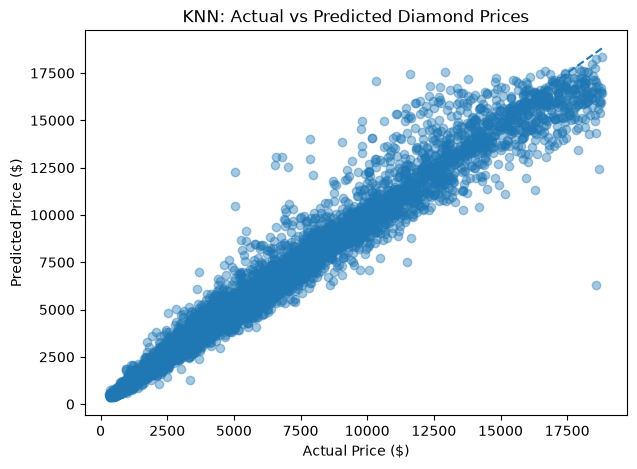

In [99]:
plt.figure(figsize=(7, 5))

plt.scatter(
    prediction_results["Actual_Price"],
    prediction_results["Predicted_Price"],
    alpha=0.4
)

min_price = min(
    prediction_results["Actual_Price"].min(),
    prediction_results["Predicted_Price"].min()
)

max_price = max(
    prediction_results["Actual_Price"].max(),
    prediction_results["Predicted_Price"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("KNN: Actual vs Predicted Diamond Prices")
plt.show()

### Visualize residuals

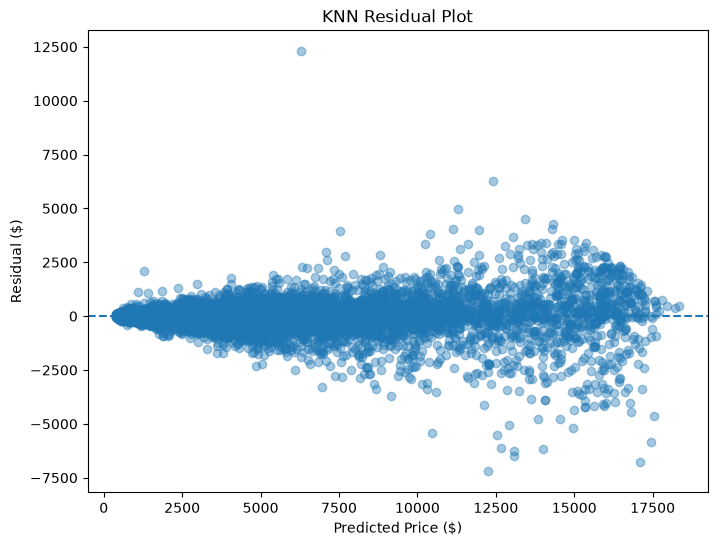

In [100]:
plt.figure(figsize=(8, 6))

plt.scatter(
    prediction_results["Predicted_Price"],
    prediction_results["Residual"],
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("KNN Residual Plot")
plt.show()

### Examine the residual distribution

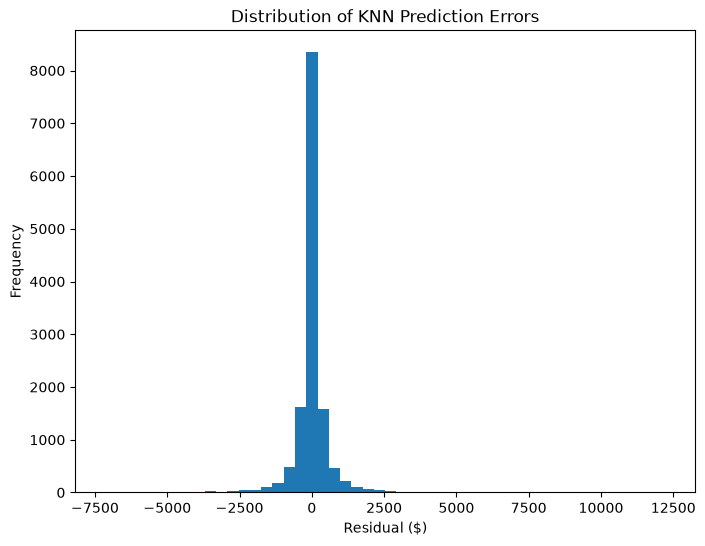

In [101]:
plt.figure(figsize=(8, 6))

plt.hist(
    prediction_results["Residual"],
    bins=50
)

plt.xlabel("Residual ($)")
plt.ylabel("Frequency")
plt.title("Distribution of KNN Prediction Errors")
plt.show()

### Identify the largest prediction errors

In [102]:
largest_errors = prediction_results.sort_values(
    by="Absolute_Error",
    ascending=False
)

largest_errors.head(10)

,Actual_Price,Predicted_Price,Residual,Absolute_Error
6981,18574,6291.715743,12282.284257,12282.284257
2863,5045,12254.129249,-7209.129249,7209.129249
5612,10340,17101.477527,-6761.477527,6761.477527
4138,6592,13065.575475,-6473.575475,6473.575475
6988,18691,12406.813733,6284.186267,6284.186267
4278,6817,13081.423934,-6264.423934,6264.423934
4776,7854,13997.076677,-6143.076677,6143.076677
4095,6535,12650.388198,-6115.388198,6115.388198
5918,11602,17462.707490,-5860.707490,5860.707490
4381,7026,12529.818555,-5503.818555,5503.818555


### Inspect the feature values of these diamonds

In [103]:
# Get positions of the 10 largest prediction errors
error_positions = largest_errors.head(10).index

# Retrieve corresponding input features
largest_error_details = X_test_fe.iloc[error_positions].copy()

# Add actual and predicted prices
largest_error_details.insert(
    0, "Actual_Price",
    y_test_clean.iloc[error_positions].values
)

largest_error_details.insert(
    1, "Predicted_Price",
    y_pred_test[error_positions]
)

# Add absolute prediction error
largest_error_details["Absolute_Error"] = (
    largest_error_details["Actual_Price"]
    - largest_error_details["Predicted_Price"]
).abs()

# Preserve original dataset row indices for traceability
largest_error_details.insert(
    0, "Original_Row_Index",
    X_test_fe.index[error_positions]
)

largest_error_details

,Original_Row_Index,Actual_Price,Predicted_Price,carat,cut,color,clarity,depth,table,x,y,z,volume,Absolute_Error
27646,27646,18574,6291.715743,2.01,Fair,G,SI1,70.6,64.0,7.43,6.64,4.69,231.382088,12282.284257
11604,11604,5045,12254.129249,1.95,Premium,H,I1,60.3,59.0,8.10,8.05,4.87,317.548350,7209.129249
22291,22291,10340,17101.477527,2.18,Very Good,E,I1,62.0,60.0,8.25,8.33,5.14,353.233650,6761.477527
16496,16496,6592,13065.575475,2.01,Very Good,H,I1,58.1,63.0,8.30,8.19,4.79,325.609830,6473.575475
27673,27673,18691,12406.813733,1.50,Very Good,G,VS2,60.7,59.0,7.31,7.38,4.46,240.607188,6284.186267
17097,17097,6817,13081.423934,2.17,Fair,G,I1,55.6,62.0,8.75,8.69,4.80,364.980000,6264.423934
19081,19081,7854,13997.076677,2.50,Fair,G,I1,64.7,57.0,8.48,8.44,5.47,391.494464,6143.076677
16341,16341,6535,12650.388198,2.21,Premium,H,I1,62.2,58.0,8.31,8.27,5.16,354.614292,6115.388198
23587,23587,11602,17462.707490,2.01,Ideal,G,SI2,61.5,55.0,8.15,8.11,5.00,330.482500,5860.707490
17489,17489,7026,12529.818555,2.05,Good,G,I1,56.9,58.0,8.46,8.30,4.77,334.939860,5503.818555


### Next diagnostic — Inspect the 9 nearest neighbors

In [104]:
# Select the first observation with the largest error
sample_index = largest_error_details.index[0]

sample_diamond = X_test_fe.loc[[sample_index]]

# Transform using the already-fitted preprocessor
preprocessor = best_knn_model.named_steps["preprocessor"]

X_train_transformed = preprocessor.transform(X_train_fe)
sample_transformed = preprocessor.transform(sample_diamond)

# Retrieve its 9 nearest training observations
knn_model = best_knn_model.named_steps["model"]

distances, neighbor_indices = knn_model.kneighbors(
    sample_transformed,
    n_neighbors=9
)

# Display the nearest neighbors
nearest_neighbors = X_train_fe.iloc[
    neighbor_indices[0]
].copy()

nearest_neighbors["Actual_Training_Price"] = (
    y_train_clean.iloc[neighbor_indices[0]].values
)

nearest_neighbors["Distance"] = distances[0]

nearest_neighbors

,carat,cut,color,clarity,depth,table,x,y,z,volume,Actual_Training_Price,Distance
16408,1.50,Fair,G,SI2,68.5,66.0,6.87,6.76,4.67,216.880404,6552,5.276909
18544,1.50,Fair,E,SI2,69.6,62.0,6.88,6.79,4.76,222.364352,7560,6.523714
15849,1.50,Fair,H,SI1,68.0,59.0,7.12,6.82,4.76,231.137984,6340,6.685883
20102,1.90,Fair,H,SI2,67.1,64.0,7.57,7.52,5.06,288.047584,8576,6.886924
11415,1.50,Fair,H,SI2,66.0,64.0,7.10,6.97,4.64,229.619680,5000,6.995857
2366,1.50,Fair,H,I1,69.3,61.0,6.99,6.81,4.78,227.537082,3175,7.062369
8014,1.50,Fair,I,SI2,70.1,58.0,6.96,6.85,4.84,230.751840,4328,7.951195
15781,2.01,Fair,G,I1,70.2,57.0,7.53,7.50,5.27,297.623250,6315,7.987371
20174,1.50,Fair,G,SI1,65.5,58.0,7.16,7.12,4.68,238.582656,8627,8.126497


## Save the complete KNN model

In [105]:
import os

os.makedirs("../models", exist_ok=True)

In [106]:
import joblib

model_path = "../models/knn_diamond_price_model.joblib"

joblib.dump(best_knn_model, model_path)

print("KNN model saved successfully!")
print("Saved location:", model_path)

KNN model saved successfully!
Saved location: ../models/knn_diamond_price_model.joblib


In [107]:
loaded_knn_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_knn_model))
print("Best parameters:", loaded_knn_model.named_steps["model"].get_params())

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Best parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 9, 'p': 1, 'weights': 'distance'}


### Test a prediction using the loaded model

In [108]:
sample_input = X_test_fe.iloc[[0]]

original_prediction = best_knn_model.predict(sample_input)
loaded_prediction = loaded_knn_model.predict(sample_input)

print("Original model prediction:", original_prediction[0])
print("Loaded model prediction:", loaded_prediction[0])

print(
    "Predictions match:",
    abs(original_prediction[0] - loaded_prediction[0]) < 1e-10
)

Original model prediction: 466.7806823000272
Loaded model prediction: 466.7806823000272
Predictions match: True
